# Prácticas 05-06  (5%, 5%) Entrega Lección Semana 11, 17:30 horas
## Trabajo grupal
### Integrantes:

| Integrante                 | Correo institucional        |
| -------------------------- | --------------------------- |
| Jonathan Barrantes         | jbarrantes40180@ufide.ac.cr |
| Joy D. Chávez Pomacaja     | jchavez60736@ufide.ac.cr    |
| María de Jesús Peña García | mpena30226@ufide.ac.cr      |
| Abby Chavarría Bolaños     | achavarria70596@ufide.ac.cr |

# Predicción de la calidad del vino.

### 1. Importación de librerías y carga de los archivos



In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
NULOS_ARTIFICIALES = 1400

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

URL_ROJO = (
    "https://raw.githubusercontent.com/JB1302/Big-Data-G2/"
    "05ac750af37859459d969eeb7bbb48bfea5627a8/Tarea/winequality-red.csv"
)
URL_BLANCO = (
    "https://raw.githubusercontent.com/JB1302/Big-Data-G2/"
    "05ac750af37859459d969eeb7bbb48bfea5627a8/Tarea/winequality-white.csv"
)

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42
TEST_SIZE = 0.20

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

# Dataset del repositorio del grupo (commit específico para mantener reproducibilidad).
URL_DATOS = (
    "https://raw.githubusercontent.com/JB1302/Big-Data-G2/"
    "05ac750af37859459d969eeb7bbb48bfea5627a8/Tarea/"
    "winequality-combinado-con-nulos.csv"
)

try:
    datos = pd.read_csv(URL_DATOS)
    print("Dataset cargado desde GitHub.")
except Exception as error:
    print("No fue posible descargar el CSV automáticamente.")
    print("Descarga 'winequality-combinado-con-nulos.csv' del repositorio")
    print("y súbelo al directorio de este notebook.")
    raise error

print(f"Dimensiones: {datos.shape[0]:,} filas × {datos.shape[1]} columnas")
display(datos.head())
display(datos.dtypes.to_frame("Tipo de dato"))

Dataset cargado desde GitHub.
Dimensiones: 6,497 filas × 13 columnas


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo_vino
0,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5,Rojo
1,7.800,0.880,0.000,2.600,0.098,25.000,67.000,0.997,3.200,0.680,9.800,5,Rojo
2,7.800,0.760,0.040,2.300,0.092,15.000,54.000,0.997,3.260,0.650,9.800,5,Rojo
3,11.200,0.280,0.560,1.900,0.075,17.000,60.000,0.998,3.160,0.580,9.800,6,Rojo
4,7.400,0.700,0.000,1.900,0.076,11.000,34.000,NaN,3.510,0.560,9.400,5,Rojo


,Tipo de dato
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


In [ ]:
## 1.1. Unificación y carga de datos

In [6]:
vino_rojo = pd.read_csv(URL_ROJO, sep=";")
vino_blanco = pd.read_csv(URL_BLANCO, sep=";")

vino_rojo.columns = vino_rojo.columns.str.strip()
vino_blanco.columns = vino_blanco.columns.str.strip()

columnas_rojo = list(vino_rojo.columns)
columnas_blanco = list(vino_blanco.columns)

if set(columnas_rojo) != set(columnas_blanco):
    raise ValueError("Los CSV rojo y blanco no tienen el mismo esquema.")

vino_blanco = vino_blanco[columnas_rojo].copy()

vino_rojo["tipo_vino"] = "Rojo"
vino_blanco["tipo_vino"] = "Blanco"

datos_originales = pd.concat(
    [vino_rojo, vino_blanco],
    axis=0,
    ignore_index=True
)

assert len(vino_rojo) == 1599, f"Filas rojas inesperadas: {len(vino_rojo)}"
assert len(vino_blanco) == 4898, f"Filas blancas inesperadas: {len(vino_blanco)}"
assert len(datos_originales) == 6497
assert datos_originales.columns.is_unique
assert datos_originales["tipo_vino"].isin(["Rojo", "Blanco"]).all()
assert datos_originales["tipo_vino"].notna().all()

print("Filas de vino rojo:", len(vino_rojo))
print("Filas de vino blanco:", len(vino_blanco))
print("Total combinado:", len(datos_originales))
print("Columnas:", len(datos_originales.columns))
print("Esquema:")
display(datos_originales.dtypes.to_frame("Tipo de dato"))
display(datos_originales.head())


Filas de vino rojo: 1599
Filas de vino blanco: 4898
Total combinado: 6497
Columnas: 13
Esquema:


,Tipo de dato
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo_vino
0,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5,Rojo
1,7.800,0.880,0.000,2.600,0.098,25.000,67.000,0.997,3.200,0.680,9.800,5,Rojo
2,7.800,0.760,0.040,2.300,0.092,15.000,54.000,0.997,3.260,0.650,9.800,5,Rojo
3,11.200,0.280,0.560,1.900,0.075,17.000,60.000,0.998,3.160,0.580,9.800,6,Rojo
4,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5,Rojo


In [7]:
validacion = pd.DataFrame({
    "Comprobación": [
        "Filas de vino rojo",
        "Filas de vino blanco",
        "Filas totales",
        "Columnas originales de características + quality",
        "Columna tipo_vino presente",
        "Nombres de columnas únicos"
    ],
    "Resultado": [
        len(vino_rojo),
        len(vino_blanco),
        len(datos_originales),
        len(columnas_rojo),
        "Sí" if "tipo_vino" in datos_originales.columns else "No",
        "Sí" if datos_originales.columns.is_unique else "No"
    ],
    "Esperado": [1599, 4898, 6497, 12, "Sí", "Sí"]
})
display(validacion)
print("Frecuencia por tipo de vino:")
display(datos_originales["tipo_vino"].value_counts().to_frame("Cantidad"))

,Comprobación,Resultado,Esperado
0,Filas de vino rojo,1599,1599
1,Filas de vino blanco,4898,4898
2,Filas totales,6497,6497
3,Columnas originales de características + quality,12,12
4,Columna tipo_vino presente,Sí,Sí
5,Nombres de columnas únicos,Sí,Sí


Frecuencia por tipo de vino:


,Cantidad
tipo_vino,
Blanco,4898
Rojo,1599


In [ ]:
## 1.2. Nulos artificiales reproducibles


In [8]:
datos = datos_originales.copy()

TARGET = "quality"
COLUMNA_TIPO = "tipo_vino"

columnas_predictoras_numericas = (
    datos.select_dtypes(include=np.number)
    .columns
    .drop(TARGET)
    .tolist()
)

assert TARGET not in columnas_predictoras_numericas
assert COLUMNA_TIPO not in columnas_predictoras_numericas

rng = np.random.default_rng(RANDOM_STATE)
n_filas = len(datos)
n_columnas = len(columnas_predictoras_numericas)
total_celdas_elegibles = n_filas * n_columnas

if NULOS_ARTIFICIALES > total_celdas_elegibles:
    raise ValueError("La cantidad de nulos solicitada supera las celdas disponibles.")

posiciones = rng.choice(
    total_celdas_elegibles,
    size=NULOS_ARTIFICIALES,
    replace=False
)

filas = posiciones // n_columnas
columnas = posiciones % n_columnas

for fila, columna in zip(filas, columnas):
    nombre_columna = columnas_predictoras_numericas[columna]
    datos.at[datos.index[fila], nombre_columna] = np.nan

nulos_generados = int(datos.isna().sum().sum())
assert nulos_generados == NULOS_ARTIFICIALES
assert datos[TARGET].isna().sum() == 0
assert datos[COLUMNA_TIPO].isna().sum() == 0

print(f"Nulos artificiales generados: {nulos_generados}")
print("Semilla utilizada:", RANDOM_STATE)
print("Columnas afectadas:")
display(datos[columnas_predictoras_numericas].isna().sum().to_frame("Nulos generados"))

Nulos artificiales generados: 1400
Semilla utilizada: 42
Columnas afectadas:


,Nulos generados
fixed acidity,136
volatile acidity,141
citric acid,121
residual sugar,115
chlorides,148
free sulfur dioxide,117
total sulfur dioxide,120
density,122
pH,127
sulphates,119


In [9]:
resumen_generacion_nulos = pd.DataFrame({
    "Nulos": datos.isna().sum(),
    "Porcentaje de la columna (%)": datos.isna().mean() * 100
})
display(resumen_generacion_nulos.query("Nulos > 0").sort_values("Nulos", ascending=False))

porcentaje_celdas_predictoras = (
    NULOS_ARTIFICIALES /
    (len(datos) * len(columnas_predictoras_numericas)) * 100
)
print(f"Porcentaje de celdas químicas numéricas con faltante: {porcentaje_celdas_predictoras:.3f}%")
print("quality sin nulos:", datos[TARGET].isna().sum() == 0)
print("tipo_vino sin nulos:", datos[COLUMNA_TIPO].isna().sum() == 0)

,Nulos,Porcentaje de la columna (%)
chlorides,148,2.278
volatile acidity,141,2.170
fixed acidity,136,2.093
alcohol,134,2.062
pH,127,1.955
density,122,1.878
citric acid,121,1.862
total sulfur dioxide,120,1.847
sulphates,119,1.832
free sulfur dioxide,117,1.801


Porcentaje de celdas químicas numéricas con faltante: 1.959%
quality sin nulos: True
tipo_vino sin nulos: True


In [ ]:
##1.3. Perfil estadístico y frecuencias

In [10]:
perfil_columnas = pd.DataFrame({
    "Tipo de dato": datos.dtypes.astype(str),
    "Valores no nulos": datos.notna().sum(),
    "Valores nulos": datos.isna().sum(),
    "Porcentaje nulos (%)": datos.isna().mean() * 100
})
display(perfil_columnas)

display(datos.describe().T)

frecuencia_tipo = datos["tipo_vino"].value_counts().to_frame("Cantidad")
frecuencia_tipo["Porcentaje (%)"] = frecuencia_tipo["Cantidad"] / len(datos) * 100

frecuencia_quality = (
    datos["quality"]
    .value_counts()
    .sort_index()
    .to_frame("Cantidad")
)
frecuencia_quality["Porcentaje (%)"] = (
    frecuencia_quality["Cantidad"] / len(datos) * 100
)

print("Frecuencia de tipo_vino:")
display(frecuencia_tipo.round(2))

print("Frecuencia de quality:")
display(frecuencia_quality.round(2))

print("Resumen global de nulos:")
resumen_global_nulos = pd.DataFrame({
    "Total de celdas": [datos.size],
    "Total de nulos": [int(datos.isna().sum().sum())],
    "Porcentaje de celdas nulas (%)": [datos.isna().sum().sum() / datos.size * 100]
})
display(resumen_global_nulos.round(3))

,Tipo de dato,Valores no nulos,Valores nulos,Porcentaje nulos (%)
fixed acidity,float64,6361,136,2.093
volatile acidity,float64,6356,141,2.170
citric acid,float64,6376,121,1.862
residual sugar,float64,6382,115,1.770
chlorides,float64,6349,148,2.278
free sulfur dioxide,float64,6380,117,1.801
total sulfur dioxide,float64,6377,120,1.847
density,float64,6375,122,1.878
pH,float64,6370,127,1.955
sulphates,float64,6378,119,1.832


,count,mean,std,min,25%,50%,75%,max
fixed acidity,"6,361.000",7.215,1.300,3.800,6.400,7.000,7.700,15.900
volatile acidity,"6,356.000",0.340,0.165,0.080,0.230,0.290,0.410,1.580
citric acid,"6,376.000",0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,"6,382.000",5.435,4.752,0.600,1.800,3.000,8.100,65.800
chlorides,"6,349.000",0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,"6,380.000",30.525,17.787,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,"6,377.000",115.825,56.527,6.000,77.500,118.000,156.000,440.000
density,"6,375.000",0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,"6,370.000",3.218,0.160,2.720,3.110,3.210,3.320,4.010
sulphates,"6,378.000",0.531,0.149,0.230,0.430,0.510,0.600,2.000


Frecuencia de tipo_vino:


,Cantidad,Porcentaje (%)
tipo_vino,,
Blanco,4898,75.390
Rojo,1599,24.610


Frecuencia de quality:


,Cantidad,Porcentaje (%)
quality,,
3,30,0.460
4,216,3.320
5,2138,32.910
6,2836,43.650
7,1079,16.610
8,193,2.970
9,5,0.080


Resumen global de nulos:


,Total de celdas,Total de nulos,Porcentaje de celdas nulas (%)
0,84461,1400,1.658


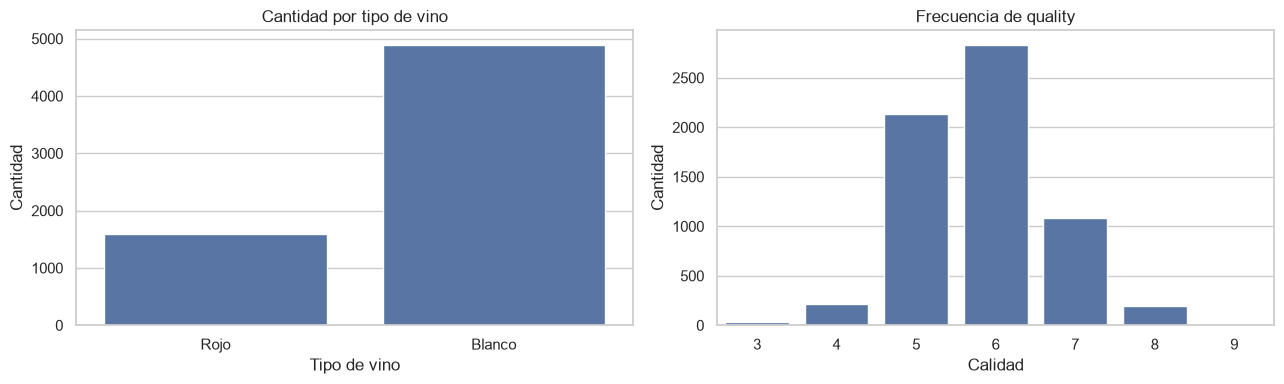

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=datos, x="tipo_vino", order=["Rojo", "Blanco"], ax=axes[0])
axes[0].set_title("Cantidad por tipo de vino")
axes[0].set_xlabel("Tipo de vino")
axes[0].set_ylabel("Cantidad")

sns.countplot(data=datos, x="quality", order=sorted(datos["quality"].dropna().unique()), ax=axes[1])
axes[1].set_title("Frecuencia de quality")
axes[1].set_xlabel("Calidad")
axes[1].set_ylabel("Cantidad")

plt.tight_layout()
plt.show()

In [ ]:
## 1.4. Histogramas y boxplots


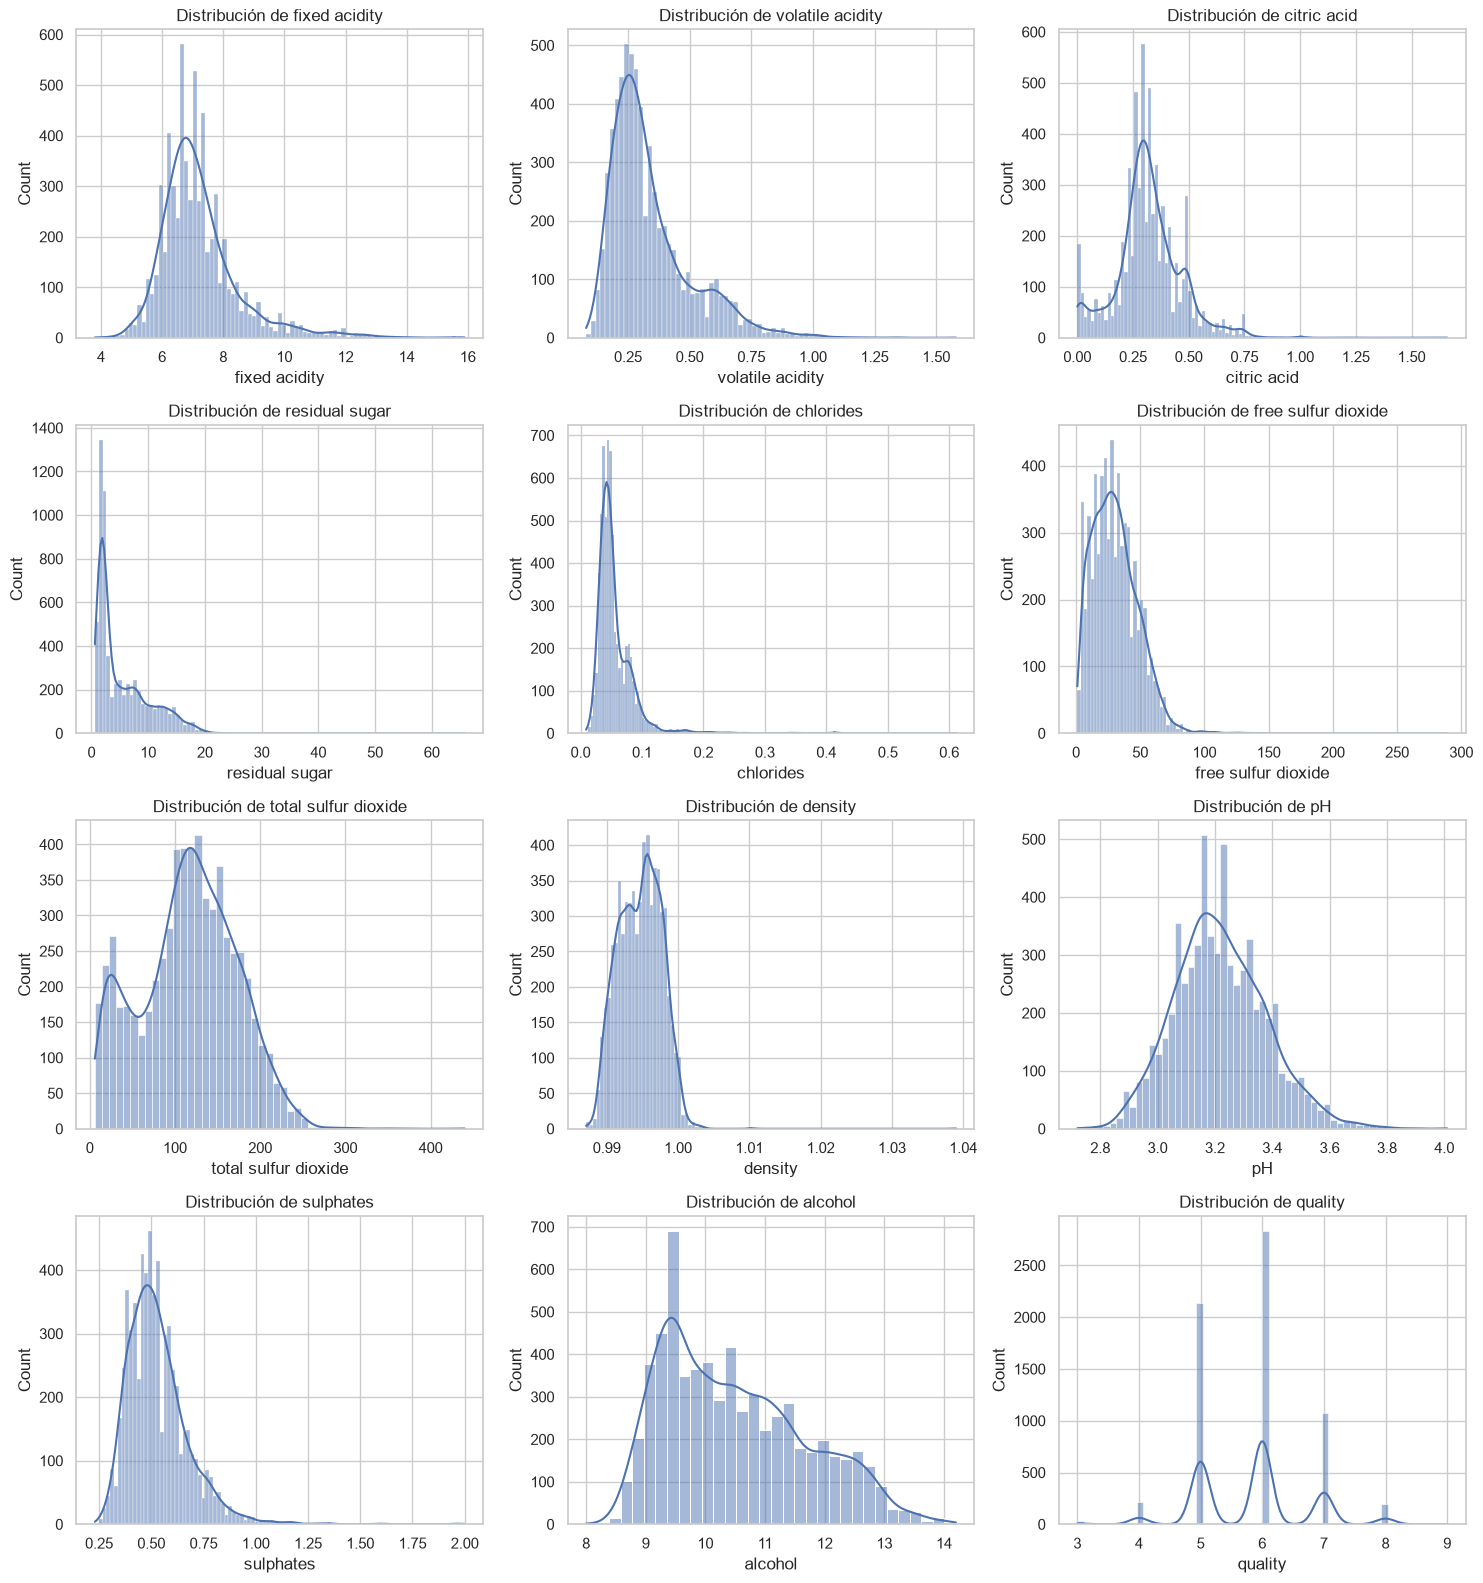

In [12]:
columnas_numericas = datos.select_dtypes(include=np.number).columns.tolist()
n_cols = 3
n_rows = int(np.ceil(len(columnas_numericas) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, columna in zip(axes, columnas_numericas):
    sns.histplot(data=datos, x=columna, kde=True, ax=ax)
    ax.set_title(f"Distribución de {columna}")

for ax in axes[len(columnas_numericas):]:
    ax.remove()

plt.tight_layout()
plt.show()

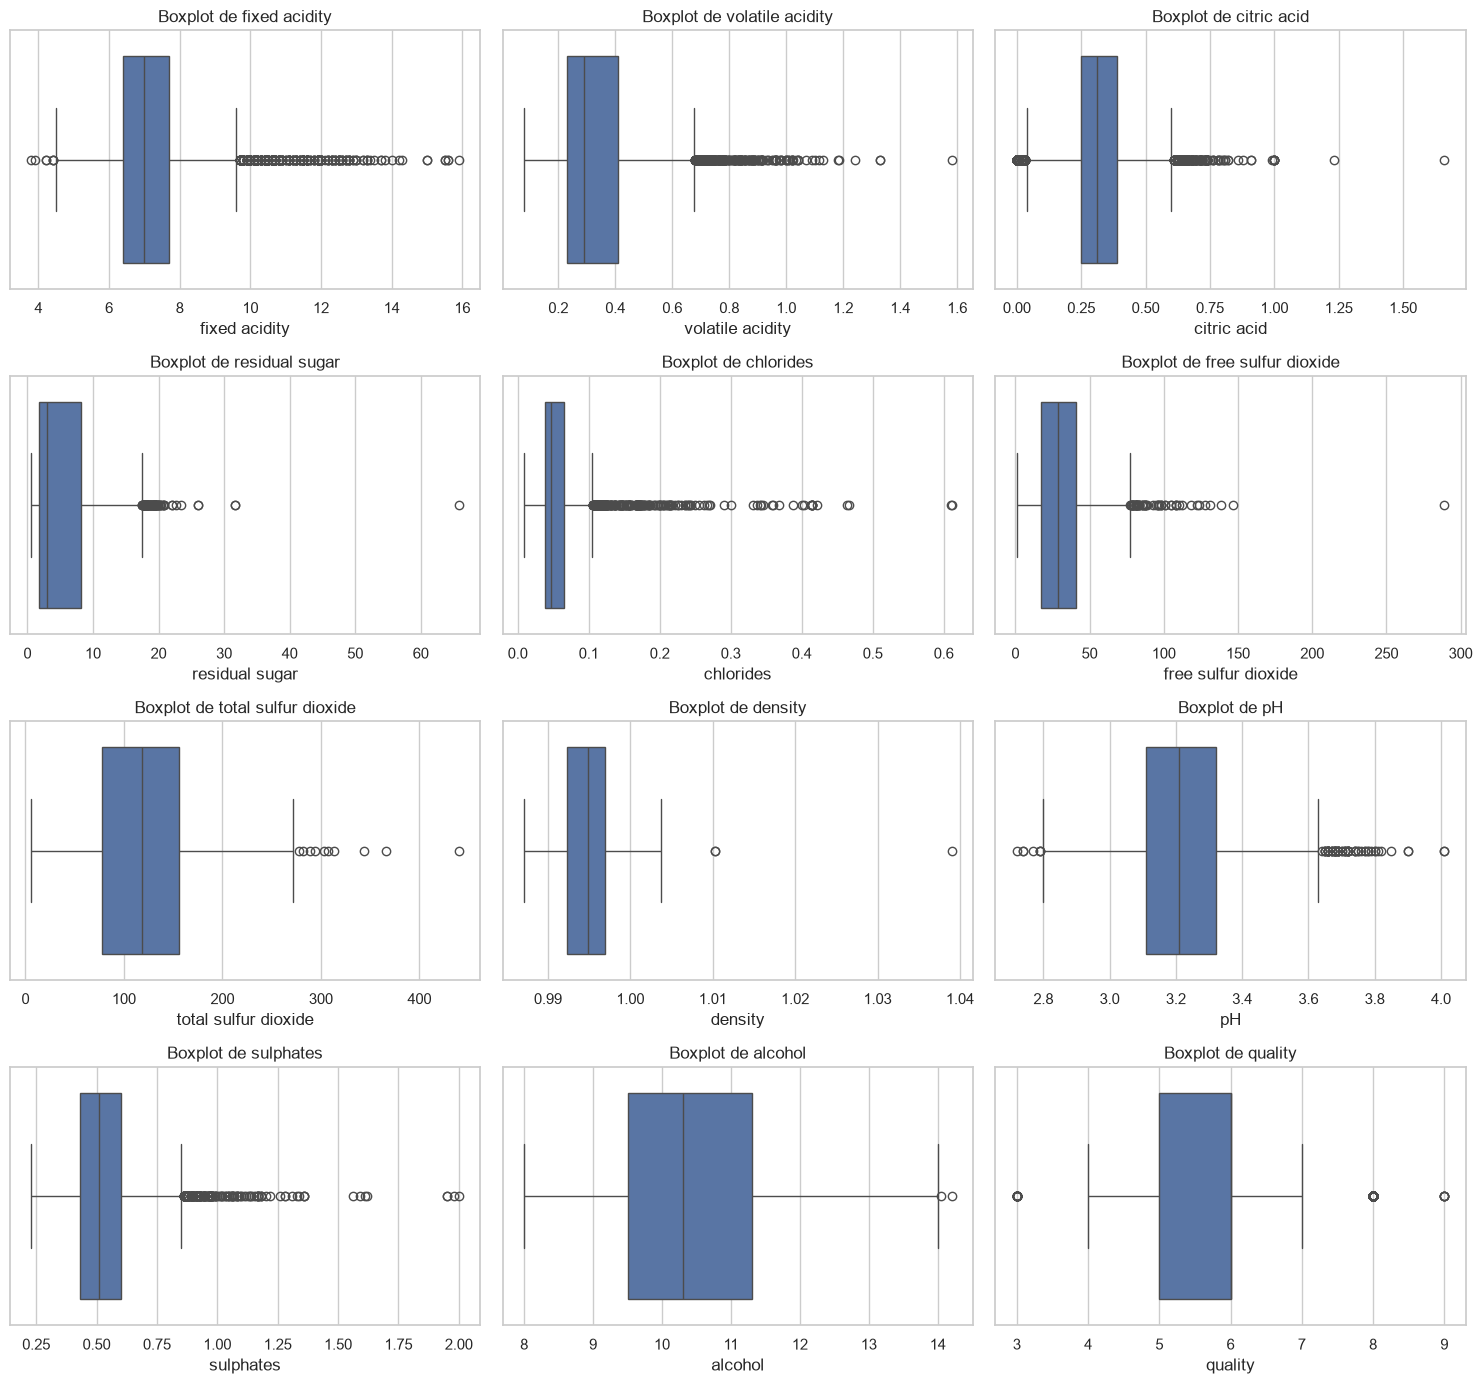

In [13]:
n_cols = 3
n_rows = int(np.ceil(len(columnas_numericas) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.5 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, columna in zip(axes, columnas_numericas):
    sns.boxplot(data=datos, x=columna, ax=ax)
    ax.set_title(f"Boxplot de {columna}")

for ax in axes[len(columnas_numericas):]:
    ax.remove()

plt.tight_layout()
plt.show()

In [14]:
filas_forma = []

for columna in columnas_numericas:
    serie = datos[columna].dropna()
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr
    extremos = ((serie < inferior) | (serie > superior)).sum()

    filas_forma.append({
        "Variable": columna,
        "Media": serie.mean(),
        "Mediana": serie.median(),
        "Desv. estándar": serie.std(),
        "Asimetría (skew)": serie.skew(),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Posibles extremos (1.5 IQR)": int(extremos),
        "Extremos (%)": extremos / len(serie) * 100
    })

perfil_forma = pd.DataFrame(filas_forma).set_index("Variable")
display(perfil_forma.sort_values("Asimetría (skew)", ascending=False).round(3))

,Media,Mediana,Desv. estándar,Asimetría (skew),Q1,Q3,IQR,Posibles extremos (1.5 IQR),Extremos (%)
Variable,,,,,,,,,
chlorides,0.056,0.047,0.035,5.452,0.038,0.065,0.027,275,4.331
sulphates,0.531,0.510,0.149,1.813,0.430,0.600,0.170,189,2.963
fixed acidity,7.215,7.000,1.300,1.726,6.400,7.700,1.300,353,5.549
volatile acidity,0.340,0.290,0.165,1.494,0.230,0.410,0.180,308,4.846
residual sugar,5.435,3.000,4.752,1.441,1.800,8.100,6.300,113,1.771
free sulfur dioxide,30.525,29.000,17.787,1.230,17.000,41.000,24.000,62,0.972
alcohol,10.491,10.300,1.193,0.562,9.500,11.300,1.800,2,0.031
density,0.995,0.995,0.003,0.512,0.992,0.997,0.005,3,0.047
citric acid,0.319,0.310,0.145,0.477,0.250,0.390,0.140,498,7.811


In [ ]:
## 1.5. Relaciones y hallazgos del EDA


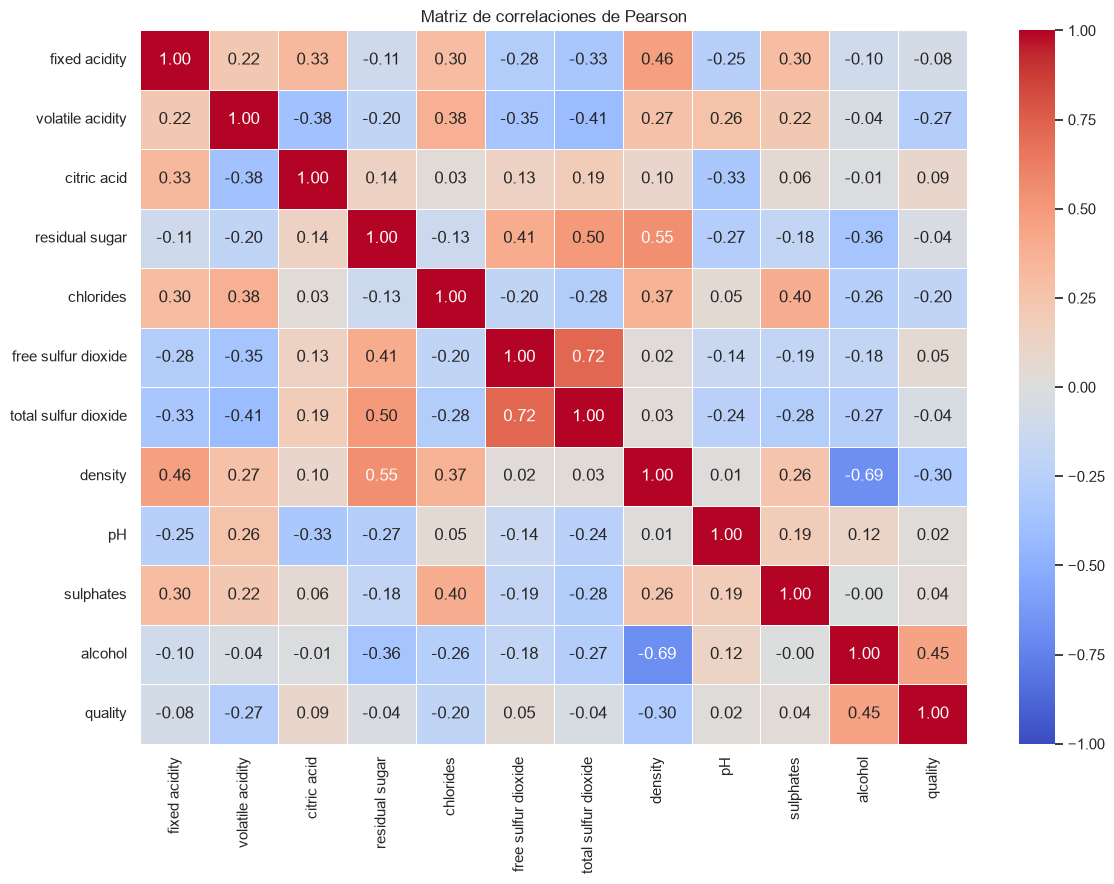

,Correlación con quality
alcohol,0.445
density,-0.304
volatile acidity,-0.268
chlorides,-0.201
citric acid,0.087
fixed acidity,-0.077
free sulfur dioxide,0.054
total sulfur dioxide,-0.042
sulphates,0.039
residual sugar,-0.035


In [15]:
matriz_correlacion = datos[columnas_numericas].corr(method="pearson")

plt.figure(figsize=(12, 9))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.4
)
plt.title("Matriz de correlaciones de Pearson")
plt.tight_layout()
plt.show()

correlaciones_quality = (
    matriz_correlacion["quality"]
    .drop("quality")
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .to_frame("Correlación con quality")
)
display(correlaciones_quality.round(3))

,Blanco,Rojo
alcohol,0.436,0.480
density,-0.306,-0.169
volatile acidity,-0.196,-0.388
chlorides,-0.212,-0.127
citric acid,-0.008,0.228
fixed acidity,-0.114,0.126
free sulfur dioxide,0.005,-0.050
total sulfur dioxide,-0.178,-0.185
sulphates,0.054,0.249
residual sugar,-0.095,0.013


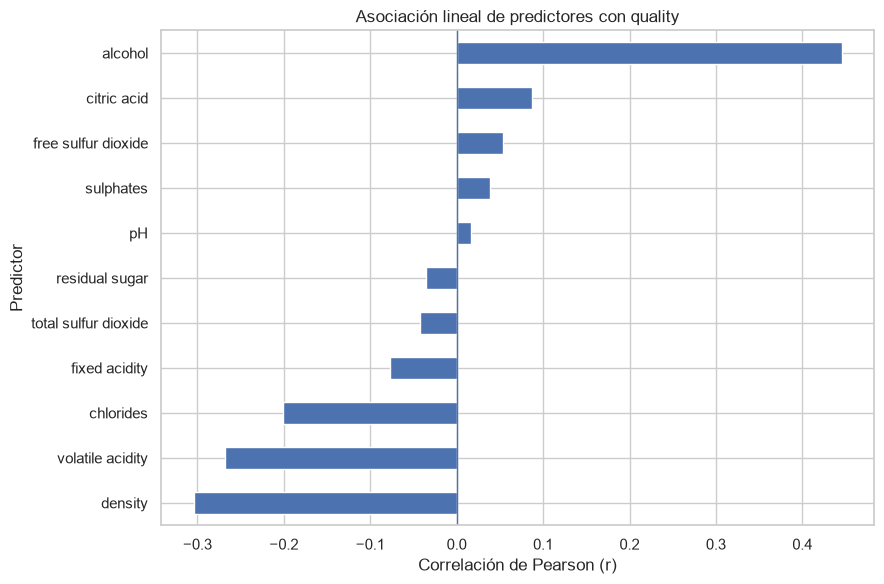

In [16]:
correlaciones_por_tipo = pd.DataFrame({
    tipo: grupo[columnas_numericas].corr(method="pearson")["quality"].drop("quality")
    for tipo, grupo in datos.groupby("tipo_vino")
})
display(correlaciones_por_tipo.loc[correlaciones_quality.index].round(3))

correlaciones_quality.sort_values("Correlación con quality").plot(
    kind="barh", figsize=(9, 6), legend=False
)
plt.axvline(0, linewidth=1)
plt.title("Asociación lineal de predictores con quality")
plt.xlabel("Correlación de Pearson (r)")
plt.ylabel("Predictor")
plt.tight_layout()
plt.show()

In [17]:
pares = (
    matriz_correlacion.where(
        np.triu(np.ones(matriz_correlacion.shape), k=1).astype(bool)
    )
    .stack()
    .rename("Correlación")
    .reset_index()
)
pares.columns = ["Variable 1", "Variable 2", "Correlación"]
pares["Magnitud absoluta"] = pares["Correlación"].abs()
display(pares.sort_values("Magnitud absoluta", ascending=False).head(10).round(3))

,Variable 1,Variable 2,Correlación,Magnitud absoluta
66,free sulfur dioxide,total sulfur dioxide,0.721,0.721
94,density,alcohol,-0.685,0.685
43,residual sugar,density,0.551,0.551
42,residual sugar,total sulfur dioxide,0.497,0.497
7,fixed acidity,density,0.465,0.465
131,alcohol,quality,0.445,0.445
18,volatile acidity,total sulfur dioxide,-0.414,0.414
41,residual sugar,free sulfur dioxide,0.405,0.405
57,chlorides,sulphates,0.397,0.397
16,volatile acidity,chlorides,0.380,0.380


In [ ]:
## 2.1. Criterio de estratificación


In [18]:
datos.columns = datos.columns.str.strip()

TARGET = "quality"
VARIABLE_ESTRATIFICACION = "tipo_vino"

if TARGET not in datos.columns:
    raise ValueError(f"No se encontró la variable objetivo '{TARGET}'.")
if VARIABLE_ESTRATIFICACION not in datos.columns:
    raise ValueError(
        f"No se encontró '{VARIABLE_ESTRATIFICACION}'. "
        "Revise el nombre de la columna en el CSV."
    )

n_y_nulos = int(datos[TARGET].isna().sum())
if n_y_nulos:
    print(f"Se excluyen {n_y_nulos} filas porque quality (y) está nula.")
    datos = datos.dropna(subset=[TARGET]).copy()

X = datos.drop(columns=[TARGET]).copy()
y = datos[TARGET].copy()

distribucion_estratos = (
    X[VARIABLE_ESTRATIFICACION]
    .value_counts(dropna=False)
    .rename("Cantidad")
    .to_frame()
)
distribucion_estratos["Porcentaje"] = (
    distribucion_estratos["Cantidad"] / len(X) * 100
)
print("Distribución de la variable elegida para estratificar:")
display(distribucion_estratos)

if X[VARIABLE_ESTRATIFICACION].isna().any():
    raise ValueError(
        "La variable tipo_vino contiene nulos. Deben resolverse antes "
        "de utilizarla como criterio de estratificación."
    )

Distribución de la variable elegida para estratificar:


,Cantidad,Porcentaje
tipo_vino,,
Blanco,4898,75.389
Rojo,1599,24.611


In [ ]:
## 2.2. División aleatoria 80/20


In [19]:
X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True
)

resumen_random = pd.DataFrame({
    "Conjunto": ["Train aleatorio", "Test aleatorio"],
    "Filas": [len(X_train_random), len(X_test_random)],
    "Porcentaje del total": [
        len(X_train_random) / len(X) * 100,
        len(X_test_random) / len(X) * 100
    ]
})
display(resumen_random)

print("Dimensiones:")
print("X_train_random:", X_train_random.shape)
print("X_test_random: ", X_test_random.shape)
print("y_train_random:", y_train_random.shape)
print("y_test_random: ", y_test_random.shape)

,Conjunto,Filas,Porcentaje del total
0,Train aleatorio,5197,79.991
1,Test aleatorio,1300,20.009


Dimensiones:
X_train_random: (5197, 12)
X_test_random:  (1300, 12)
y_train_random: (5197,)
y_test_random:  (1300,)


In [ ]:
## 2.3. División estratificada y comparación


Dimensiones de la división estratificada:
X_train_strat: (5197, 12)
X_test_strat:  (1300, 12)
y_train_strat: (5197,)
y_test_strat:  (1300,)


Conjunto,Completo,Test aleatorio,Test estratificado,Train aleatorio,Train estratificado
Tipo de vino,,,,,
Blanco,75.390,73.770,75.380,75.790,75.390
Rojo,24.610,26.230,24.620,24.210,24.610


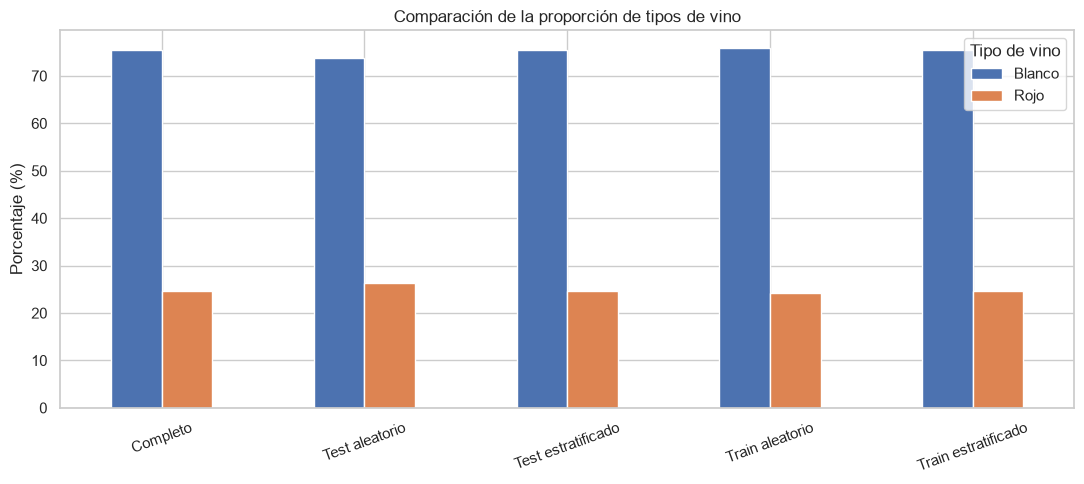

In [20]:
X_train_strat, X_test_strat, y_train_strat, y_test_strat = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=X[VARIABLE_ESTRATIFICACION]
)

print("Dimensiones de la división estratificada:")
print("X_train_strat:", X_train_strat.shape)
print("X_test_strat: ", X_test_strat.shape)
print("y_train_strat:", y_train_strat.shape)
print("y_test_strat: ", y_test_strat.shape)

def tabla_proporciones_tipo(conjuntos, variable):
    filas = []
    for nombre, conjunto in conjuntos.items():
        proporciones = conjunto[variable].value_counts(normalize=True, dropna=False)
        for categoria, proporcion in proporciones.items():
            filas.append({
                "Conjunto": nombre,
                "Tipo de vino": categoria,
                "Proporción (%)": proporcion * 100
            })
    return pd.DataFrame(filas)

tabla_tipos = tabla_proporciones_tipo(
    {
        "Completo": X,
        "Train aleatorio": X_train_random,
        "Test aleatorio": X_test_random,
        "Train estratificado": X_train_strat,
        "Test estratificado": X_test_strat
    },
    VARIABLE_ESTRATIFICACION
)
display(
    tabla_tipos.pivot(
        index="Tipo de vino", columns="Conjunto", values="Proporción (%)"
    ).round(2)
)

# Gráfico de proporciones por partición.
grafico_tipos = tabla_tipos.pivot(
    index="Conjunto", columns="Tipo de vino", values="Proporción (%)"
)
ax = grafico_tipos.plot(kind="bar", figsize=(11, 5))
ax.set_title("Comparación de la proporción de tipos de vino")
ax.set_ylabel("Porcentaje (%)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=20)
plt.legend(title="Tipo de vino")
plt.tight_layout()
plt.show()

In [21]:
# Error de representación: diferencia absoluta respecto de la proporción
# observada en el conjunto completo, expresada en puntos porcentuales.
proporcion_total = X[VARIABLE_ESTRATIFICACION].value_counts(normalize=True)

filas_error = []
for nombre, conjunto in {
    "Train aleatorio": X_train_random,
    "Test aleatorio": X_test_random,
    "Train estratificado": X_train_strat,
    "Test estratificado": X_test_strat
}.items():
    prop = conjunto[VARIABLE_ESTRATIFICACION].value_counts(normalize=True)
    for categoria in proporcion_total.index:
        filas_error.append({
            "Conjunto": nombre,
            "Tipo de vino": categoria,
            "Error absoluto (p.p.)": abs(prop.get(categoria, 0) - proporcion_total[categoria]) * 100
        })

errores_proporcion = pd.DataFrame(filas_error)
display(errores_proporcion.pivot(
    index="Tipo de vino", columns="Conjunto", values="Error absoluto (p.p.)"
).round(3))

print("Error absoluto medio de proporciones (puntos porcentuales):")
display(
    errores_proporcion.groupby("Conjunto")["Error absoluto (p.p.)"]
    .mean().to_frame("Error medio").round(4)
)


Conjunto,Test aleatorio,Test estratificado,Train aleatorio,Train estratificado
Tipo de vino,,,,
Blanco,1.619,0.004,0.405,0.001
Rojo,1.619,0.004,0.405,0.001


Error absoluto medio de proporciones (puntos porcentuales):


,Error medio
Conjunto,
Test aleatorio,1.619
Test estratificado,0.004
Train aleatorio,0.405
Train estratificado,0.001


In [22]:
# Diagnóstico adicional de la variable objetivo después de dividir.
# Importante: quality NO se empleó para estratificar.
resumen_quality = pd.DataFrame({
    "Conjunto": [
        "Completo", "Train aleatorio", "Test aleatorio",
        "Train estratificado", "Test estratificado"
    ],
    "Media quality": [
        y.mean(), y_train_random.mean(), y_test_random.mean(),
        y_train_strat.mean(), y_test_strat.mean()
    ],
    "Desv. estándar quality": [
        y.std(), y_train_random.std(), y_test_random.std(),
        y_train_strat.std(), y_test_strat.std()
    ]
}).set_index("Conjunto")

display(resumen_quality.round(3))

,Media quality,Desv. estándar quality
Conjunto,,
Completo,5.818,0.873
Train aleatorio,5.815,0.877
Test aleatorio,5.834,0.860
Train estratificado,5.824,0.871
Test estratificado,5.795,0.883


In [ ]:
## 2.4. Diagnóstico de valores nulos en train


In [23]:
X_train = X_train_strat.copy()
X_test = X_test_strat.copy()
y_train = y_train_strat.copy()
y_test = y_test_strat.copy()

nulos_train = X_train.isna().sum()
porcentaje_nulos_train = X_train.isna().mean() * 100

diagnostico_nulos = pd.DataFrame({
    "Tipo de variable": X_train.dtypes.astype(str),
    "Nulos en train": nulos_train,
    "Porcentaje de nulos (%)": porcentaje_nulos_train
}).sort_values("Nulos en train", ascending=False)

display(diagnostico_nulos)

print("Total de celdas nulas en X_train:", int(nulos_train.sum()))
print("Total de celdas de predictores en X_train:", X_train.size)
print("Porcentaje global de celdas nulas en X_train:",
      round(X_train.isna().sum().sum() / X_train.size * 100, 3), "%")

,Tipo de variable,Nulos en train,Porcentaje de nulos (%)
chlorides,float64,121,2.328
volatile acidity,float64,116,2.232
alcohol,float64,113,2.174
pH,float64,106,2.040
fixed acidity,float64,104,2.001
total sulfur dioxide,float64,103,1.982
density,float64,99,1.905
sulphates,float64,97,1.866
free sulfur dioxide,float64,95,1.828
residual sugar,float64,95,1.828


Total de celdas nulas en X_train: 1140
Total de celdas de predictores en X_train: 62364
Porcentaje global de celdas nulas en X_train: 1.828 %


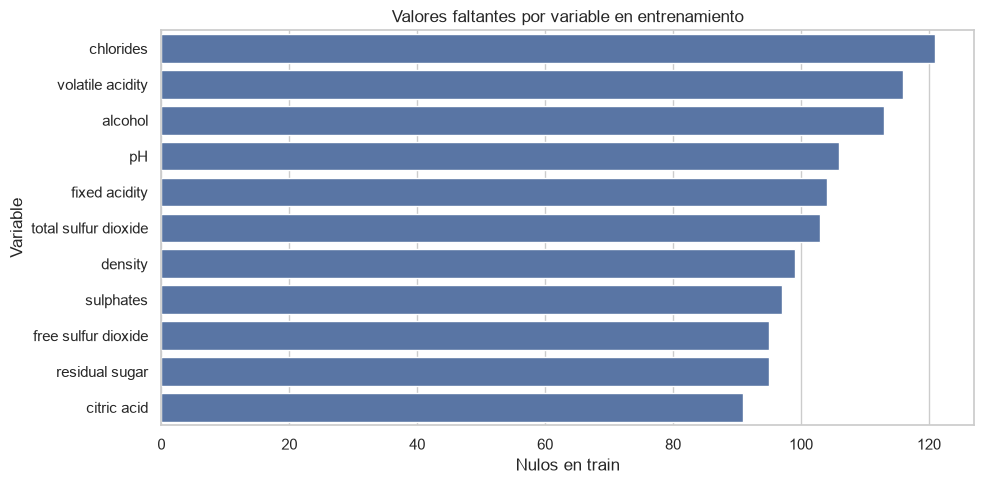

In [24]:
# Visualización de nulos por variable (solo variables con faltantes).
nulos_para_grafico = diagnostico_nulos.query("`Nulos en train` > 0")

if len(nulos_para_grafico):
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=nulos_para_grafico.reset_index(names="Variable"),
        x="Nulos en train",
        y="Variable"
    )
    plt.title("Valores faltantes por variable en entrenamiento")
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron valores nulos en los predictores de train.")

In [ ]:
## 2.5. Imputación sin fuga de información


In [25]:
columnas_numericas = X_train.select_dtypes(include=np.number).columns.tolist()
columnas_categoricas = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Variables numéricas:", columnas_numericas)
print("Variables categóricas:", columnas_categoricas)

imputador_numerico = SimpleImputer(strategy="median")
imputador_categorico = SimpleImputer(strategy="most_frequent")

X_train_imputado = X_train.copy()
if columnas_numericas:
    X_train_imputado[columnas_numericas] = imputador_numerico.fit_transform(
        X_train[columnas_numericas]
    )
if columnas_categoricas:
    X_train_imputado[columnas_categoricas] = imputador_categorico.fit_transform(
        X_train[columnas_categoricas]
    )

X_test_imputado = X_test.copy()
if columnas_numericas:
    X_test_imputado[columnas_numericas] = imputador_numerico.transform(
        X_test[columnas_numericas]
    )
if columnas_categoricas:
    X_test_imputado[columnas_categoricas] = imputador_categorico.transform(
        X_test[columnas_categoricas]
    )

print("Imputación aplicada. No se ajustó ningún imputador con test.")

Variables numéricas: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Variables categóricas: ['tipo_vino']
Imputación aplicada. No se ajustó ningún imputador con test.


In [26]:
# Resumen de nulos antes y después de la imputación.
comparacion_nulos = pd.DataFrame({
    "Train antes": X_train.isna().sum(),
    "Train después": X_train_imputado.isna().sum(),
    "Test antes": X_test.isna().sum(),
    "Test después": X_test_imputado.isna().sum()
})
display(comparacion_nulos)

print("Nulos totales en train antes:", int(X_train.isna().sum().sum()))
print("Nulos totales en train después:", int(X_train_imputado.isna().sum().sum()))
print("Nulos totales en test antes:", int(X_test.isna().sum().sum()))
print("Nulos totales en test después:", int(X_test_imputado.isna().sum().sum()))

# Verificación automática: la imputación debe dejar cero nulos en X.
assert X_train_imputado.isna().sum().sum() == 0, "Quedaron nulos en train."
assert X_test_imputado.isna().sum().sum() == 0, "Quedaron nulos en test."
print("Verificación superada: train y test no contienen nulos en X.")

,Train antes,Train después,Test antes,Test después
fixed acidity,104,0,32,0
volatile acidity,116,0,25,0
citric acid,91,0,30,0
residual sugar,95,0,20,0
chlorides,121,0,27,0
free sulfur dioxide,95,0,22,0
total sulfur dioxide,103,0,17,0
density,99,0,23,0
pH,106,0,21,0
sulphates,97,0,22,0


Nulos totales en train antes: 1140
Nulos totales en train después: 0
Nulos totales en test antes: 260
Nulos totales en test después: 0
Verificación superada: train y test no contienen nulos en X.


In [27]:
# Mostrar los valores de imputación aprendidos SOLO desde train.
valores_imputacion = {}

if columnas_numericas:
    valores_imputacion.update(
        dict(zip(columnas_numericas, imputador_numerico.statistics_))
    )
if columnas_categoricas:
    valores_imputacion.update(
        dict(zip(columnas_categoricas, imputador_categorico.statistics_))
    )

tabla_valores_imputacion = pd.DataFrame({
    "Variable": list(valores_imputacion.keys()),
    "Valor utilizado para imputar": list(valores_imputacion.values())
})
display(tabla_valores_imputacion)

,Variable,Valor utilizado para imputar
0,fixed acidity,7.000
1,volatile acidity,0.290
2,citric acid,0.310
3,residual sugar,2.900
4,chlorides,0.047
5,free sulfur dioxide,29.000
6,total sulfur dioxide,118.000
7,density,0.995
8,pH,3.210
9,sulphates,0.510
